# Chapter 2: Designing the Test: How Big, How Long, What to Count

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Designing the Test: How Big, How Long, What to Count](https://books.sugiv.fyi/lift/design-test.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import design as D, style

style.apply()
pd.set_option("display.precision", 3)


def glue_num(name, value):
    glue(name, float(value), display=False)


N_NEEDED = D.n_per_arm(D.BASELINE, D.TRUE_LIFT)
ENROL_DAYS = 2 * N_NEEDED / D.NEW_LEARNERS_PER_DAY
glue_num("base_pct", 100 * D.BASELINE)
glue_num("lift_pts", 100 * D.TRUE_LIFT)
glue_num("n_needed", round(N_NEEDED, -2))
glue_num("enrol_days", ENROL_DAYS)
glue_num("ch1_power", 100 * D.simulate_power(10_000)[0])

Here's the finding first. Chapter 1's Streak Shield test missed a real effect, and it was always likely to. To detect a lift of 1.5 points on a day-30 retention rate of 38%, with the usual 80% power, Parlo needs about **15,700 learners per arm**. Chapter 1 used 10,000, which gives only about 61% power. (Chapter 1 quoted 57%, computed from the effect in its particular sample of learners; either way, close to a coin toss.) At 2,000 new learners a day that's about 16 days of enrolment, which I round up to **three full weeks**, plus 30 days of waiting before the last learner's day-30 retention is known.

That one calculation is most of test design. The rest of this chapter covers the decisions around it: which metric, how small an effect is worth finding, what counts as one observation, and how to make guardrails mean something. Each comes with a mistake I've seen real teams ship.

> **Note**
>
> Every number comes from `lift/sim/design.py`, which reuses Chapter 1's learners. The true lift of Streak Shield, 1.54 points, is known only because this is a simulation. In real life you pick the effect you *want* to detect, before the test.

## Start with the decision, then pick the metrics

Before any power calculation, write down what you'll do with each possible result. That forces three kinds of metric:

| Role | Streak Shield | Juno prompt change | What it does |
|---|---|---|---|
| **Decision metric** | Day-30 retention | Lesson completion rate | One number that decides ship or don't ship. Size the test for it. |
| **Guardrails** | Notification opt-outs, crash rate | Cost per lesson, response latency | Things that must not get worse. They can block a launch, so they need power too. |
| **Diagnostics** | Shields used per learner | Turns per lesson | Explain *why* the result happened. Never used to decide. |

One decision metric matters more than it sounds. With five "primary" metrics, something will look good by chance and the team will ship on it. Chapter 6 covers the maths of that; the cure is to decide in advance.

A good decision metric is **attributable** (the change can plausibly move it), **sensitive** (it moves enough to measure) and **aligned** with what the business actually wants. Day-30 retention is aligned but slow. Chapter 6 shows how to use a faster surrogate, built from week-one behaviour, without fooling yourself; Chapter 8 shows what happens when a fast proxy (opens) points the wrong way.

## How many learners? Power, by simulation

Power is the chance that a test detects an effect that's really there. The cleanest way to understand it is to run the test thousands of times on simulated data and count how often it comes out significant. Here's that for Streak Shield, with three possible true lifts:

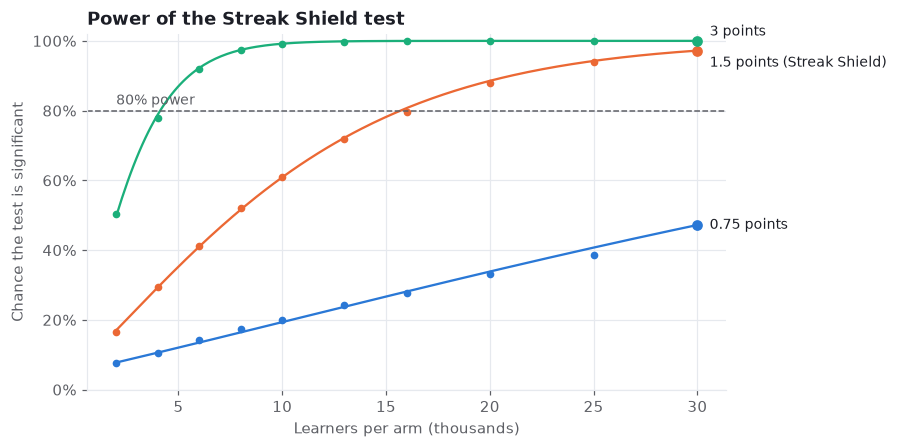

In [3]:
sizes = np.array([2_000, 4_000, 6_000, 8_000, 10_000, 13_000, 16_000, 20_000, 25_000, 30_000])
lifts = {"0.75 points": 0.0075, "1.5 points (Streak Shield)": D.TRUE_LIFT, "3 points": 0.03}
colours = [style.SERIES[0], style.SERIES[1], style.SERIES[2]]

fig, ax = plt.subplots()
for (label, lift), colour in zip(lifts.items(), colours):
    sim = [D.simulate_power(n, lift=lift, seed=i)[0] for i, n in enumerate(sizes)]
    grid = np.linspace(sizes[0], sizes[-1], 200)
    d = lift / np.sqrt(D.BASELINE * (1 - D.BASELINE))
    ax.plot(grid / 1000, pg.power_ttest(d=d, n=grid), color=colour, linewidth=1.5)
    ax.plot(sizes / 1000, sim, "o", color=colour, markersize=4)
    end = pg.power_ttest(d=d, n=grid[-1])
    ax.plot([grid[-1] / 1000], [end], "o", color=colour, markersize=6, clip_on=False)
    nudge = {"3 points": 6, "1.5 points (Streak Shield)": -8}.get(label, 0)
    ax.annotate(label, xy=(grid[-1] / 1000, end), xytext=(8, nudge), textcoords="offset points",
                va="center", fontsize=9, color=style.INK, annotation_clip=False)
ax.axhline(0.8, color=style.MUTED, linewidth=1, linestyle="--")
ax.annotate("80% power", xy=(sizes[0] / 1000, 0.8), xytext=(0, 4), textcoords="offset points",
            fontsize=9, color=style.MUTED)
ax.set(title="Power of the Streak Shield test",
       xlabel="Learners per arm (thousands)", ylabel="Chance the test is significant",
       ylim=(0, 1.02))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.show()

The dots are simulated tests (4,000 each); the lines are `pg.power_ttest`, Pingouin's power formula. They agree, which is the point: the formula is a shortcut for exactly this simulation.

Two things to notice. First, the 1.5-point curve crosses 80% at about 15,700 learners per arm. Second, **halving the effect quadruples the sample**: the 0.75-point curve is still under 50% at 30,000 learners per arm. Small effects are expensive, and most product effects are small.

Here's the calculation you'd actually run before a test, in two lines:

In [4]:
p, lift = D.BASELINE, D.TRUE_LIFT
d = lift / np.sqrt(p * (1 - p))        # Cohen's d for a difference in rates
print(f"learners per arm: {pg.power_ttest(d=d, power=0.8):,.0f}")

learners per arm: 15,696


<details>
<summary><b>The formula behind the curves</b></summary>

For two arms of $n$ learners each and a rate near $p$, the difference in observed rates has standard error

$$
\text{SE} = \sqrt{\frac{2\,p(1-p)}{n}}.
$$

A two-sided test at $\alpha = 0.05$ is significant when the observed difference exceeds $1.96\,\text{SE}$. To clear that bar 80% of the time, the true lift $\delta$ must sit $1.96 + 0.84 = 2.80$ standard errors from zero. Solving for $n$:

$$
n = \frac{2\,p(1-p)\,(1.96 + 0.84)^2}{\delta^2} \approx \frac{16\,p(1-p)}{\delta^2}.
$$

The $\delta^2$ in the denominator is why halving the effect quadruples the sample. The "16" version is a handy rule of thumb (Kohavi et al., 2020).

</details>

## Flip it: what can my traffic detect?

In practice the question usually runs backwards. Traffic is fixed: Parlo gets about 2,000 new learners a day. The question is how small an effect a test of a given length can detect. That's the **minimum detectable effect (MDE)**:

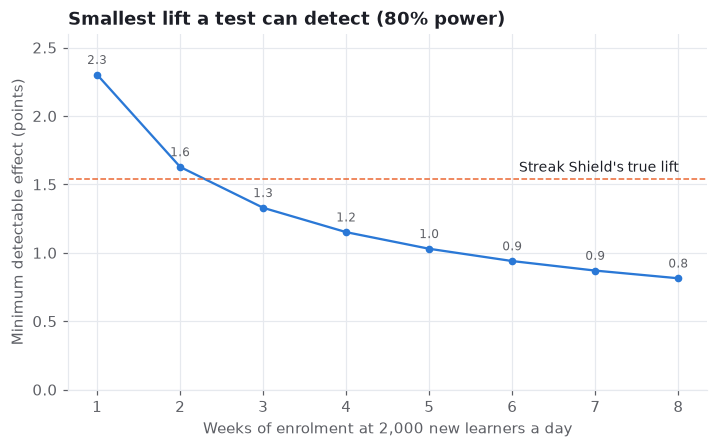

In [5]:
weeks = np.arange(1, 9)
n_arm = weeks * 7 * D.NEW_LEARNERS_PER_DAY / 2
mde_pts = 100 * D.mde(D.BASELINE, n_arm)

fig, ax = plt.subplots()
ax.plot(weeks, mde_pts, "-o", color=style.SERIES[0], markersize=4, linewidth=1.5)
ax.axhline(100 * D.TRUE_LIFT, color=style.SERIES[1], linewidth=1, linestyle="--")
ax.annotate("Streak Shield's true lift", xy=(weeks[-1], 100 * D.TRUE_LIFT), xytext=(0, 5),
            textcoords="offset points", ha="right", fontsize=9, color=style.INK)
for w, m in zip(weeks, mde_pts):
    ax.annotate(f"{m:.1f}", xy=(w, m), xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=8, color=style.MUTED)
ax.set(title="Smallest lift a test can detect (80% power)",
       xlabel="Weeks of enrolment at 2,000 new learners a day",
       ylabel="Minimum detectable effect (points)", ylim=(0, 2.6))
ax.set_xticks(weeks)
plt.show()

In [6]:
glue_num("mde_1wk", mde_pts[0])
glue_num("mde_3wk", mde_pts[2])
glue_num("mde_8wk", mde_pts[7])

One week can only detect lifts of 2.3 points or more. Three weeks gets down to 1.3, just below the true lift. Eight weeks reaches 0.8, but the curve is flattening: the MDE shrinks with the *square root* of the sample, so doubling the test only cuts it by about 30%.

The MDE isn't something you hope for. It's a business question: **what's the smallest lift that would change the decision?** If Streak Shield costs a week of engineering a year to maintain, maybe a 0.5-point lift isn't worth having and you never need to detect it. If it's free, any positive lift is worth shipping and you might accept a lower bar. Write the number down *before* the test, with the reason.

A few duration rules I follow, whatever the formula says:

- **Run whole weeks.** Learners on Sunday evening aren't learners on Tuesday morning. A 10-day test over-weights some weekdays.
- **Count the follow-up.** A day-30 metric means the last learner enrolled needs 30 more days. Three weeks of enrolment is a seven-week project.
- **Fix the length in advance.** Stopping the day the p-value dips below 0.05 inflates false positives badly. Chapter 5 shows how to peek safely with sequential tests.
- **Don't trust week one.** New features attract curiosity clicks. Chapter 6 covers novelty effects.

## Juno: count learners, not lessons

Now the most common design bug I see on agent teams. Juno's team randomises **learners**: each learner gets one prompt for the whole test, which is right, because a learner switching prompts mid-lesson would be confusing. But they measure **completion per lesson**, and a learner does many lessons.

The tempting analysis treats every lesson as an independent coin flip. It isn't. A learner who finds Juno easy completes most of their lessons; a struggling learner fails most of theirs. Lessons from the same learner move together, so 10,000 lessons from 2,000 learners carry much less information than 10,000 independent lessons.

To see how much this matters, run **A/A tests**: both arms get the same prompt, so any "significant" result is a false alarm. At the usual 5% threshold, an honest method should cry wolf 5% of the time.

In [7]:
fp = D.aa_false_positive(n=2_000, reps=2_000)
pd.Series(fp).to_frame("false-positive rate (should be 5%)").style.format("{:.1%}")

,false-positive rate (should be 5%)
lessons as independent,20.6%
delta method (per learner),5.7%


In [8]:
glue_num("fp_naive", 100 * fp["lessons as independent"])
glue_num("fp_delta", 100 * fp["delta method (per learner)"])

Treating lessons as independent produces a "significant" difference between two identical prompts in **21% of tests**, four times the promised rate. The **delta method** gets 5.7%, close to the promised 5%. If your team has been shipping prompt changes on per-lesson significance, some of those wins were noise.

The delta method (Deng et al., 2018) treats each learner as one observation, with two numbers: lessons done and lessons completed. The completion rate is the ratio of their totals, and its standard error comes from how much each learner's completions deviate from what the overall rate predicts for their lesson count. In code it's short:

In [9]:
lessons, done = D.juno_learners(2_000, 0.78, seed=42)
lessons, done = lessons[0], done[0]

rate = done.sum() / lessons.sum()
resid = done - rate * lessons                     # one number per learner
se_delta = resid.std(ddof=1) / np.sqrt(len(lessons)) / lessons.mean()
se_naive = np.sqrt(rate * (1 - rate) / lessons.sum())
print(f"completion {rate:.3f}  |  SE per lesson {se_naive:.4f}  |  SE delta method {se_delta:.4f}")

completion 0.784  |  SE per lesson 0.0041  |  SE delta method 0.0060


As a cross-check that doesn't need any algebra, resample whole learners with Pingouin's bootstrap. Passing lessons and completions as a pair keeps each learner's two numbers together:

In [10]:
ci, boot = pg.compute_bootci(lessons, done, func=lambda x, y: y.sum() / x.sum(),
                             paired=True, n_boot=2000, seed=1, return_dist=True)
print(f"bootstrap SE {boot.std():.4f}, 95% CI {ci[0]:.3f} to {ci[1]:.3f}")

bootstrap SE 0.0060, 95% CI 0.770 to 0.800


The bootstrap and the delta method agree, and both are about half as wide again as the per-lesson answer. The bootstrap is easier to trust; the delta method is a few lines of numpy and runs in microseconds on a billion rows, which is why experimentation platforms use it.

<details>
<summary><b>Where the delta method formula comes from</b></summary>

Write the rate as a ratio of two per-learner means, $r = \bar Y / \bar X$, with $X_i$ the lessons and $Y_i$ the completions of learner $i$. A first-order Taylor expansion around the true means gives

$$
r - r_0 \approx \frac{1}{\mu_X}\left(\bar Y - r_0 \bar X\right) = \frac{1}{\mu_X}\cdot\frac{1}{n}\sum_i \left(Y_i - r_0 X_i\right),
$$

an ordinary mean of independent per-learner terms. So

$$
\operatorname{Var}(r) \approx \frac{\operatorname{Var}(Y_i - r X_i)}{n\,\mu_X^2},
$$

which is the `resid.std() / sqrt(n) / lessons.mean()` line above. The same trick handles any ratio metric: revenue per session, tokens per resolved ticket, cost per completed lesson.

</details>

The general rule: **analyse at the level you randomised.** If the coin is flipped per learner, the learner is your unit of observation, however you choose to aggregate. Agent systems make this easy to get wrong, because the natural log line is a turn, a tool call or a conversation, not a user. Ratio metrics like cost per lesson or latency per turn all need the same treatment.

## Guardrails need power too

Juno's team has a second idea: a **shorter system prompt** that cuts token cost by 30%. The worry is that completion drops. The guardrail is written down in advance: *completion must not fall by more than 2 points.*

A quick test with 300 learners per arm finishes in a day. The result: no significant difference. Ship it?

That's the trap. "No significant difference" from a small test means the test couldn't tell, not that the change is harmless. Asking the right question, **"can we rule out a drop bigger than 2 points?"**, is called a **non-inferiority test**. It's a one-sided test against the margin instead of against zero.

Here's what happens across 1,000 simulated tests of each size, where the short prompt's true cost is 1 point of completion: real, but inside the margin.

In [11]:
rows = []
for n in [300, 2_000, 10_000]:
    g = D.guardrail_test(n, margin=0.02, reps=1_000, seed=5)
    rows.append({"learners per arm": n,
                 "says 'no significant difference'": (g["p_any_difference"] > 0.05).mean(),
                 "proves drop is under 2 points": (g["p_non_inferior"] < 0.05).mean(),
                 "typical 95% CI width (points)": 100 * np.median(g["ci_hi"] - g["ci_lo"])})
guard = pd.DataFrame(rows).set_index("learners per arm")
guard.style.format({"says 'no significant difference'": "{:.0%}",
                    "proves drop is under 2 points": "{:.0%}",
                    "typical 95% CI width (points)": "{:.1f}"})

,says 'no significant difference',proves drop is under 2 points,typical 95% CI width (points)
learners per arm,,,
300,92%,12%,9.0
2000,82%,33%,3.5
10000,31%,83%,1.6


In [12]:
glue_num("g300_nodiff", 100 * guard.iloc[0, 0])
glue_num("g300_ni", 100 * guard.iloc[0, 1])
glue_num("g300_width", guard.iloc[0, 2])
glue_num("g10k_ni", 100 * guard.iloc[2, 1])
glue_num("g10k_sig", 100 - 100 * guard.iloc[2, 0])
sigma = D.per_learner_sd(0.78)
n_guard = 2 * sigma ** 2 * (D.z_crit(sides=1)) ** 2 / (0.02 - 0.01) ** 2
glue_num("n_guard", round(n_guard, -2))
glue_num("sigma_juno", sigma)

With 300 learners per arm, 92% of tests say "no significant difference", and the team would read that as "no harm". But the confidence interval is about 9 points wide, wide enough to hide a drop more than twice the margin. Only 12% of those small tests can actually *show* the drop is under 2 points.

The big test flips it. With 10,000 learners per arm the short prompt's 1-point drop is **statistically significant** in 69% of tests, and yet 83% of the time the test also proves it's under the 2-point margin. Both are true: there *is* a cost, and it's an acceptable one. That's the honest answer, and it lets the team weigh one point of completion against 30% of the token bill, as Chapter 7 does for model choice.

Sizing a guardrail works like sizing any test, with the gap between the true difference and the margin playing the role of the effect. Use the per-learner spread from the delta method, 0.28, which already allows for each learner doing several correlated lessons:

In [13]:
sigma = D.per_learner_sd(0.78)
gap = 0.02 - 0.01                       # margin minus the drop we expect
d = gap / sigma
print(f"learners per arm: {pg.power_ttest(d=d, power=0.8, alternative='greater'):,.0f}")

learners per arm: 9,698


About 9,700 learners per arm. If you can't afford that, you can't afford to claim the guardrail held. Either widen the margin (honestly, before the test) or say "not tested" instead of "no harm".

## The one-page design

Everything above fits on one page, written before the test starts. Here's Streak Shield's:

| | |
|---|---|
| **Hypothesis** | Streak Shield raises day-30 retention by protecting streaks through one missed day. |
| **Unit and split** | New learners, 50/50 by a hash of learner id. The shield is offered from day 8, after each learner's first week. |
| **Decision metric** | Day-30 retention, per learner. |
| **Effect worth detecting** | 1.5 points (below that, maintenance cost outweighs the benefit). |
| **Size and length** | About 15,700 per arm: 3 full weeks of enrolment, then 30 days of follow-up. |
| **Guardrails** | Notification opt-outs (non-inferiority margin 0.3 points), crash rate. |
| **Decision rule** | Ship if retention is significantly positive and no guardrail fails. Otherwise don't. |
| **Checks before reading** | Sample ratio and A/A checks (Chapter 3). |

The point of the page isn't bureaucracy. It's that every number on it was chosen before anyone saw a result, so nobody can choose them afterwards to fit the result.

> **In the wild**
>
> Kohavi, Tang and Xu (Kohavi et al., 2020) report that at Microsoft, Bing and Google most ideas, once tested, fail to improve the metrics they were designed to improve. The ones that work usually move them by small amounts. That's why sizing for the effect you *hope* for is so costly: real effects are mostly small, and underpowered tests miss them.

## Pitfalls

- **Sizing for the effect you hope for.** Teams plug in a 5-point lift because it makes the test short. Then the real 1.5-point effect goes undetected and the feature is called a failure.
- **Analysing lessons when you randomised learners.** Per-lesson, per-turn or per-session standard errors are too small whenever the coin was flipped per user. Use the delta method or a learner-level bootstrap.
- **"No significant harm" from a small test.** Absence of evidence isn't evidence of absence. Use a non-inferiority margin and size the guardrail for it.
- **Partial weeks and early stopping.** Both bias the result in ways the p-value doesn't show.
- **Many decision metrics.** Pick one. The rest are guardrails or diagnostics.

## Exercises

1. **Cheaper power.** What happens to the sample size if Parlo accepts 70% power instead of 80%? What about $\alpha = 0.10$? When would either trade be reasonable?
2. **Heavier users.** In `sim/design.py`, set `LEARNER_SPREAD` to 1 (learners differ more) and rerun the A/A test. What happens to the per-lesson false-positive rate, and why?
3. **Cost per lesson.** Juno's cost per lesson is another ratio: total token cost over total lessons, randomised per learner. Write its delta-method standard error, reusing the residual trick.
4. **The guardrail you can afford.** Juno sees about 3,000 learners a day. What non-inferiority margin can a one-week test support at 80% power?

## Further reading

Kohavi, Tang and Xu (Kohavi et al., 2020) cover metric design, power and guardrails from long experience at Microsoft, Amazon, Google and LinkedIn. Deng, Knoblich and Lu (Deng et al., 2018) is the practical guide to the delta method for ratio metrics, including the per-user versus per-event trap.